# 3.3 EDA — Riesgo de prórroga en contratos públicos (SECOP II)

**Base v0** (22-oct-2026): 167.997 contratos firmados entre 2019 y 2025, ~24.000 por año. La muestra **no es proporcional por año**: las tasas agrupadas describen la muestra, no la población. Fuente: SECOP II, datos.gov.co (`jbjy-vk9h`, `p6dx-8zbt`), licencia CC BY-SA 4.0.

**Etiqueta v0:** `y = y_dias = dias_adicionados > 0`. La F1 mostró que subestima los positivos: la etiqueta definitiva es "ampliación del plazo" (tasa ~24 %). Todo resultado que dependa de `y` se marca **[PROVISIONAL v0]** y no se interpreta como conclusión. La base v1 llega el domingo en la noche.

**Alcance de hoy:** §2 calidad, §3 distribuciones/deriva/correlación, §4 duración y madurez, §5 etiqueta, §6 H1–H7 (tablas y gráficas, sin interpretación), §7.1 privacidad del proveedor y §9 decisiones. §4.3, la interpretación de §5–§6, §7.2 y §8 se completan con v1.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import eda
from src import features as F
from src.base import validar_esquema

eda.config_graficas()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

BASE = RAIZ / "data" / "processed" / "v1_A" / "base_contratos.parquet"
base, meta = eda.cargar_base(BASE)
validar_esquema(base)
X = F.construir_features(base)
PREFIJO = eda.prefijo_provisional(meta)

print("base:", base.shape, "| features:", X.shape)
print("version:", meta["version"], "| corte:", meta["fechas_de_corte"]["fecha_de_corte_de_la_censura"])
print("anios:", sorted(base["anio_firma"].unique().tolist()))
print("entidades:", base["nit_entidad"].nunique(), "| maduros:", round(100 * base["eval_madura"].mean(), 1), "%")

base: (452494, 50) | features: (452494, 39)
version: v1 | corte: 2026-10-26
anios: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
entidades: 3034 | maduros: 99.2 %


## 1. Carga y mapa de hipótesis

La base cumple el esquema 2a y `construir_features` devuelve las 39 features. El EDA separa lo que no depende de la etiqueta (calidad, distribución, deriva, duración, privacidad) de lo que sí (H1–H7 y etiqueta).

| Hipótesis | Señal al firmar | Feature(s) | Sección |
|---|---|---|---|
| H1. Procesos apresurados | Días entre publicación y firma | `dias_publicacion_a_firma` | 6.1 |
| H2. Poca competencia | Respuestas, oferentes, invitados | `p_respuestas_al_procedimiento`, `p_conteo_de_respuestas_a_ofertas`, `p_proveedores_invitados` | 6.2 |
| H3. Modalidad | Directa frente a competitivas | `modalidad_de_contratacion`, `justificacion_modalidad_de` | 6.3 |
| H4. Anualidad | Firma en el último trimestre | `mes_firma`, `firma_ultimo_trimestre`, `fin_planeado_cruza_anio` | 6.4 |
| H5. Plazos subestimados | Duración planeada | `p_dur_dias`, `p_unidad_de_duracion` | 6.5 |
| H6. Hábitos de la entidad | Tasa histórica de la entidad | `nit_entidad` (TargetEncoder) | 6.6 |
| H7. Tipo de objeto | UNSPSC y tipo de contrato | `unspsc_segmento`, `unspsc_familia`, `tipo_de_contrato`, `len_objeto` | 6.7 |

`y` no se usa en §2–§4; solo en §4.3, §5, §6 y §7.2, que quedan marcadas.

## 2. Calidad de datos

No depende de la etiqueta: se puede cerrar con v0. Se re-ejecuta con v1 para refrescar cifras.

### 2.1 Faltantes

**Qué se observa.** Los faltantes son bajos y vienen en bloques: 215 contratos (0,13 %) no tienen fila de Procesos (todas las `p_*` faltan), `fecha_de_inicio_del_contrato` falta en 1.732 (1,03 %), la duración planeada en 436 (0,26 %) y `unspsc_familia`/`unspsc_segmento` en 1.375 (0,82 %), todos con código `UNSPECIFIED`. `y_modif` falta al 100 % porque la v0 no trae Modificaciones; es esperado.

**Decisión.** Imputar dentro del `Pipeline`, con la mediana/moda aprendida solo en train, y usar indicadores de bloque (`sin_proceso`, `sin_inicio`, `sin_duracion`). No borrar filas: los faltantes son pocos y borrarlas sesgaría la muestra.

Columnas de la base con faltantes:


,columna,tipo,n,faltantes,pct_faltantes,n_unicos
0,N_mes,float64,452494,452494,100.00,0
1,fecha_de_inicio_del_contrato,datetime64[us],452494,4059,0.90,2803
2,eval_dur_planeada_dias,float32,452494,799,0.18,935
3,eval_fin_planeado,datetime64[us],452494,799,0.18,3976
4,p_fecha_de_publicacion_del,datetime64[us],452494,380,0.08,2708
5,p_conteo_de_respuestas_a_ofertas,float64,452494,349,0.08,43
6,p_duracion,float64,452494,349,0.08,847
7,p_numero_de_lotes,float64,452494,349,0.08,136
8,p_precio_base,float64,452494,349,0.08,146892
9,p_proveedores_con_invitacion,float64,452494,349,0.08,162


Features con faltantes:


,columna,tipo,n,faltantes,pct_faltantes,n_unicos
0,dias_firma_a_inicio,float64,452494,4059,0.90,634
1,unspsc_familia,object,452494,3806,0.84,376
2,unspsc_segmento,object,452494,3806,0.84,56
3,fin_planeado_cruza_anio,float64,452494,799,0.18,2
4,p_dur_dias,float64,452494,799,0.18,935
5,dias_publicacion_a_firma,float64,452494,380,0.08,569
6,log_precio_base,float64,452494,349,0.08,146885
7,p_conteo_de_respuestas_a_ofertas,float64,452494,349,0.08,43
8,p_numero_de_lotes,float64,452494,349,0.08,136
9,p_proveedores_con_invitacion,float64,452494,349,0.08,162


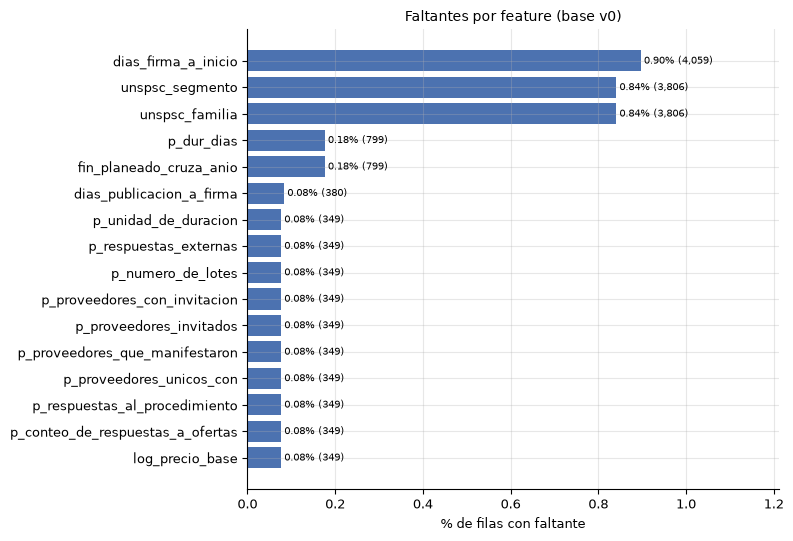

In [2]:
cols_base = [c for c in base.columns if c not in ["id_contrato", "proceso_de_compra"]]
faltantes_base = eda.resumen_faltantes(base, cols_base)
faltantes_x = eda.resumen_faltantes(X, F.FEATURES)

print("Columnas de la base con faltantes:")
display(faltantes_base[faltantes_base["faltantes"] > 0])
print("Features con faltantes:")
display(faltantes_x[faltantes_x["faltantes"] > 0])
eda.graficar_faltantes(faltantes_x, titulo="Faltantes por feature (base v0)")
plt.show()

### 2.2 Valores imposibles

**Qué se observa.** No hay `id_contrato` duplicados, fechas basura, PII ni columnas de fuga. Los problemas están en duración y montos: 8.694 contratos (5,18 %) tienen duración planeada ≤ 0, 66 (0,04 %) pasan de 3.650 días y el máximo es 83,4 millones de días; 26 precios base son negativos, 1.740 son cero y el máximo es 3,4 billones. Además, 2.680 contratos (1,6 %) tienen fin planeado anterior a la firma: en todos el inicio es anterior a la firma y la duración no alcanza a cubrir ese retroceso (518 tienen duración ≤ 0).

**Decisión.** Tratar duración ≤ 0 como faltante y recortar a [1, 3.650] días; no eliminar contratos. `construir_features` ya recorta `dias_firma_a_inicio` y `dias_publicacion_a_firma`, pero no `p_dur_dias`. Los precios negativos quedan en 0 después de `clip(lower=0)` en `log_precio_base`, así que no se pueden separar de los ceros reales: el Pipeline crea `precio_no_positivo = log_precio_base == 0` y documenta la limitación.

In [3]:
imposibles = eda.revisar_valores_imposibles(base)
display(imposibles[imposibles["n"] > 0].reset_index(drop=True))
print("Los chequeos que no aparecen dieron 0.")

,chequeo,n,pct,detalle
0,fecha_de_inicio nula,4059,0.90,
1,inicio mas de 365 dias antes de la firma,256,0.06,
2,inicio mas de 365 dias despues de la firma,102,0.02,
3,p_fecha_de_publicacion nula,380,0.08,
4,p_duracion nula,349,0.08,
5,p_duracion <= 0,24586,5.43,
6,duracion planeada nula,799,0.18,
7,duracion planeada <= 0,24566,5.43,
8,duracion planeada > 3650 dias,125,0.03,
9,p_precio_base nulo,349,0.08,


Los chequeos que no aparecen dieron 0.


### 2.3 Atípicos

**Qué se observa.** Las colas largas están en duración, precio, pago adelantado y competencia. La duración planeada (`eval_dur_planeada_dias`) tiene 5,19 % en cero y 1,44 % fuera de 1,5 IQR, con máximo de 83,4 millones de días; `p_duracion` tiene 7,81 % fuera de 1,5 IQR; `p_precio_base` tiene 14,6 % fuera de 1,5 IQR y máximo de 3,4 billones; `p_proveedores_invitados` llega a 7.388 y `p_respuestas_al_procedimiento` a 254. `len_objeto` está truncado en 500 caracteres.

**Decisión.** No eliminar outliers: son pocos y pueden ser señal. Para kNN/SVM, `log1p` + `RobustScaler`; para HGB, dejar los valores crudos y usar el recorte suave de §2.2. Recortar `p_proveedores_invitados` en el percentil 99,9 solo para modelos de distancia.

,columna,n,n_cero,pct_cero,n_neg,min,p1,p50,p99,max,n_iqr_alto,pct_iqr_alto
0,p_precio_base,452145,3497,0.77,10,"-34,693,400,216.00","810,960.00","19,600,000.00","3,529,646,400.00","2,500,616,113,000.00",62166,13.75
1,p_respuestas_al_procedimiento,452145,408894,90.43,0,0.00,0.00,0.00,9.00,254.00,43251,9.57
2,p_numero_de_lotes,452145,414147,91.60,0,0.00,0.00,0.00,37.00,216.00,37998,8.40
3,p_duracion,452145,24586,5.44,0,0.00,0.00,15.00,350.00,"135,963,450.00",36371,8.04
4,p_proveedores_invitados,452145,442688,97.91,0,0.00,0.00,0.00,4.00,"7,229.00",9457,2.09
5,eval_dur_planeada_dias,451695,24566,5.44,0,0.00,0.00,120.00,420.00,"4,078,903,552.00",4427,0.98
6,valor_de_pago_adelantado,452494,451976,99.89,0,0.00,0.00,0.00,0.00,"25,178,078,596.00",518,0.11
7,len_objeto,452494,0,0.00,0,1.00,40.00,234.00,500.00,500.00,0,0.00


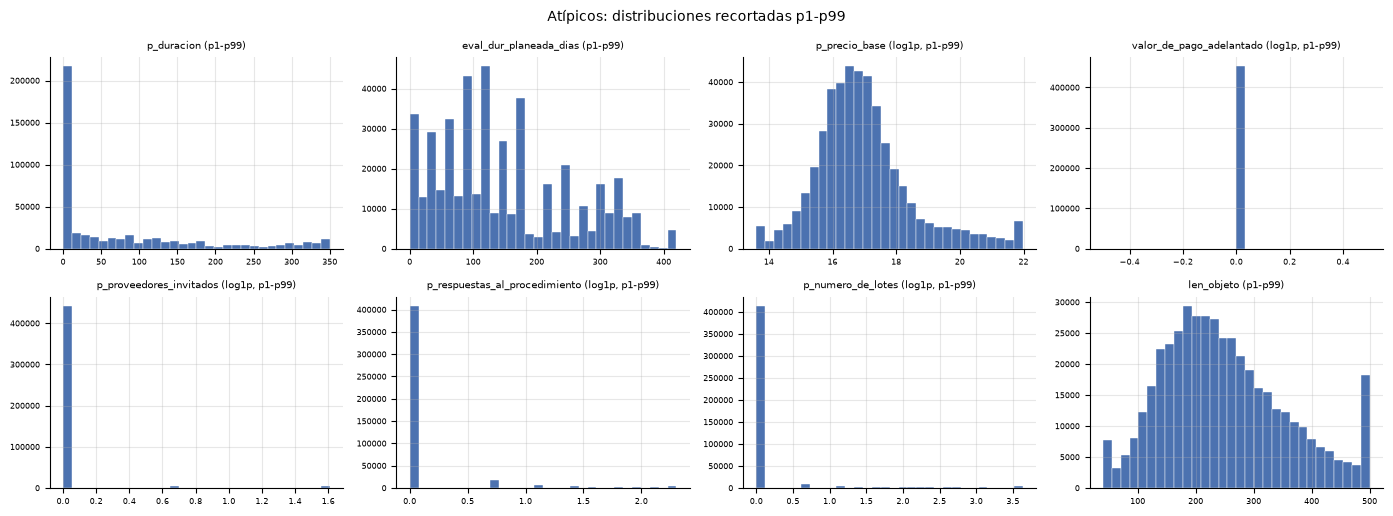

In [4]:
base_atipicos = base.assign(len_objeto=X["len_objeto"])
cols_atipicos = ["p_duracion", "eval_dur_planeada_dias", "p_precio_base", "valor_de_pago_adelantado",
                 "p_proveedores_invitados", "p_respuestas_al_procedimiento", "p_numero_de_lotes", "len_objeto"]
atipicos = eda.resumen_atipicos(base_atipicos, cols_atipicos)
display(atipicos.round(3))
eda.graficar_histogramas(
    base_atipicos, cols_atipicos, ncols=4,
    escala_log=("p_precio_base", "valor_de_pago_adelantado", "p_proveedores_invitados",
                "p_respuestas_al_procedimiento", "p_numero_de_lotes"),
    titulo="Atípicos: distribuciones recortadas p1-p99",
)
plt.show()

### 2.4 Cardinalidad de las categóricas

**Qué se observa.** `nit_entidad` (2.568), `ciudad` (664), `unspsc_familia` (373) y `unspsc_segmento` (56) concentran la cardinalidad alta. En el resto, las categorías raras (<1 %) son pocas: `justificacion` 31 categorías/4,1 % de filas, `departamento` 14/6,2 %, `sector` 7/3,0 %, `tipo_de_contrato` 17/2,4 %, `modalidad` 7/1,8 %, `tipodocproveedor` 7/0,9 %. `ciudad` tiene 648 categorías raras y 24,8 % de las filas; `nit_entidad` tiene 2.559 categorías con <1 % y 77,1 % de las filas, pero es la señal de H6 y va con TargetEncoder, no con one-hot.

**Decisión.** Para one-hot/kNN/SVM: agrupar categorías <1 % en `OTROS` y mantener `No Definido` como categoría o faltante explícito. Para HGB: categorías nativas con tope (200) o códigos ordinales; `nit_entidad` solo con `TargetEncoder` dentro del `Pipeline`.

,columna,n_unicos,nulos,top,top_pct,n_categorias_lt_1pct,pct_filas_lt_1pct
0,nit_entidad,3034,0,899999034,5.62,3024,76.59
1,ciudad,735,0,No Definido,21.37,718,26.26
2,unspsc_familia,376,3806,8011,63.52,364,14.94
3,unspsc_segmento,56,3806,80,72.00,50,10.90
4,justificacion_modalidad_de,41,0,Servicios profesionales y apoyo a la gestión,73.36,36,5.76
5,departamento,34,0,Distrito Capital de Bogotá,33.50,13,5.18
6,sector,26,0,Servicio Público,24.91,8,2.73
7,tipo_de_contrato,24,0,Prestación de servicios,85.75,19,2.64
8,modalidad_de_contratacion,15,0,Contratación directa,76.75,10,2.46
9,tipodocproveedor,10,0,Cédula de Ciudadanía,84.25,8,0.53


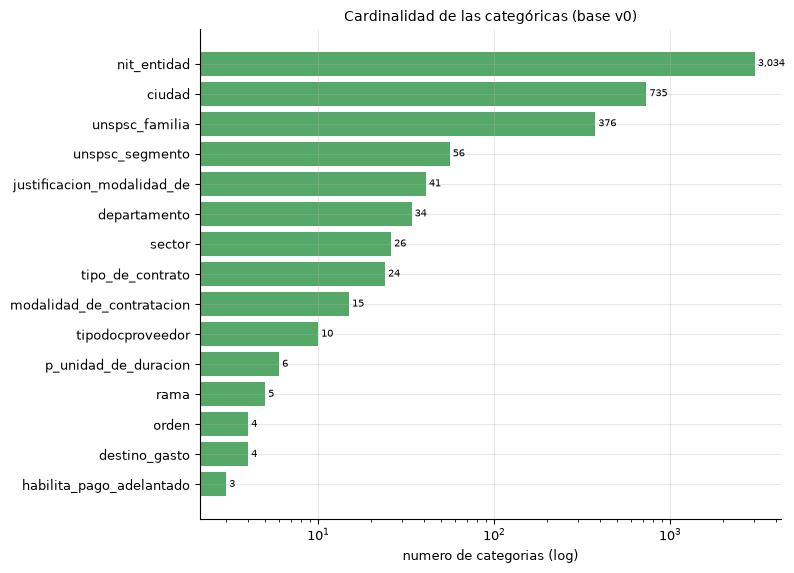

In [5]:
card = eda.cardinalidad_categoricas(X, F.FEATURES_CAT)
display(card.round(2))
eda.graficar_cardinalidad(card, top=15, titulo="Cardinalidad de las categóricas (base v0)")
plt.show()

## 3. Distribución de features y deriva por año

No depende de la etiqueta. Se revisan las 18 numéricas y las 21 categóricas, y se comparan 2019–2025 para detectar deriva.

### 3.1 Distribución de las numéricas

**Qué se observa.** La mayoría son cero-infladas: `log_pago_adelantado` 99,8 % en cero, `p_proveedores_invitados` 96,4 %, `p_numero_de_lotes` 91,1 %, `p_respuestas_al_procedimiento` 79,3 %. `p_dur_dias` tiene mediana 120 días y p95 333; `log_precio_base` mediana 16,79 (unos 19,5 millones) y p99 22,30 (unos 4,9 mil millones). El calendario está repartido; `firma_ultimo_trimestre` es 25 %.

**Decisión.** Para kNN/SVM: usar tal cual `log_precio_base` y `log_pago_adelantado` (ya vienen en `log1p`), aplicar `log1p` a los conteos crudos y `RobustScaler` después; para HGB: valores crudos y flags de cero. No imputar los ceros de competencia: son "sin respuesta", no faltantes.

,columna,n,media,std,min,p1,p5,p50,p95,p99,max,pct_cero
0,log_pago_adelantado,452494,0.02,0.62,0.00,0.00,0.00,0.00,0.00,0.00,23.95,99.89
1,len_objeto,452494,248.78,106.88,1.00,40.00,99.00,234.00,466.00,500.00,500.00,0.00
2,dias_firma_a_inicio,448435,2.88,17.27,-365.00,-8.00,0.00,1.00,13.00,37.00,365.00,32.91
3,mes_firma,452494,5.55,3.68,1.00,1.00,1.00,5.00,12.00,12.00,12.00,0.00
4,dia_semana,452494,2.29,1.53,0.00,0.00,0.00,2.00,5.00,6.00,6.00,15.56
5,firma_ultimo_trimestre,452494,0.20,0.40,0.00,0.00,0.00,0.00,1.00,1.00,1.00,80.13
6,fin_planeado_cruza_anio,451695,0.24,0.43,0.00,0.00,0.00,0.00,1.00,1.00,1.00,76.26
7,log_precio_base,452145,16.89,2.16,0.00,13.61,14.91,16.79,20.22,21.98,28.55,0.78
8,p_dur_dias,451695,"12,066.52","6,298,973.53",0.00,0.00,0.00,120.00,337.00,420.00,"4,078,903,500.00",5.44
9,dias_publicacion_a_firma,452114,5.88,26.67,0.00,0.00,0.00,1.00,23.00,70.00,"1,000.00",36.63


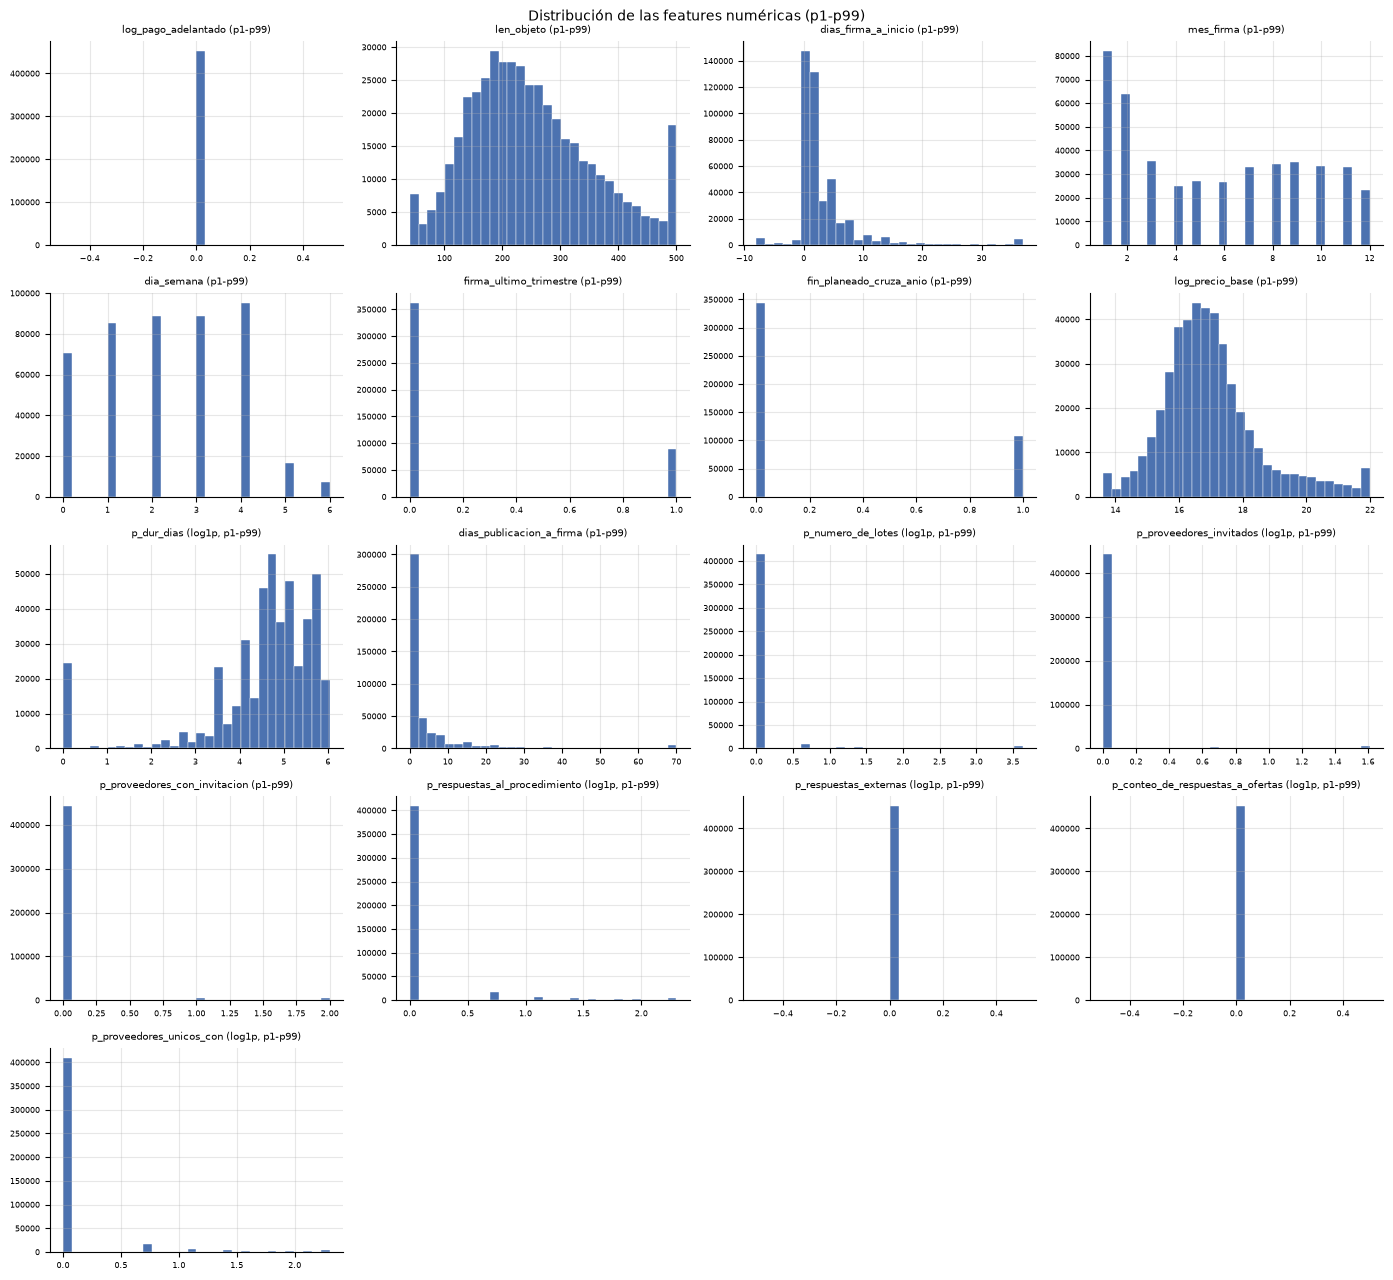

In [6]:
num_plot = [c for c in F.FEATURES_NUM if X[c].nunique() > 1]
display(eda.distribucion_numericas(X, F.FEATURES_NUM).round(2))
eda.graficar_histogramas(
    X, num_plot, ncols=4,
    escala_log=("p_dur_dias", "p_numero_de_lotes", "p_proveedores_invitados",
                "p_respuestas_al_procedimiento", "p_respuestas_externas",
                "p_conteo_de_respuestas_a_ofertas", "p_proveedores_unicos_con"),
    titulo="Distribución de las features numéricas (p1-p99)",
)
plt.show()

### 3.2 Composición de las categóricas

**Qué se observa.** El contrato típico es prestación de servicios (77,6 %), contratación directa (65,0 %), proveedor con cédula (74,6 %), en Bogotá/Valle/Antioquia. `No Definido` aparece en `ciudad` 23,5 %, `departamento` 2,0 %, `destino_gasto` 0,5 % y `tipodocproveedor` 0,4 %. `documentos_tipo` usa "No" y "No definido" como categorías distintas; `destino_gasto` usa "No Definido" y "No aplica".

**Decisión.** Normalizar texto (minúsculas, sin espacios) y unificar "No definido"/"No Definido" en una sola categoría; `No Definido` en `ciudad` se trata como categoría (no como faltante) porque puede informar la calidad del registro. Las categorías raras se agrupan como en §2.4.

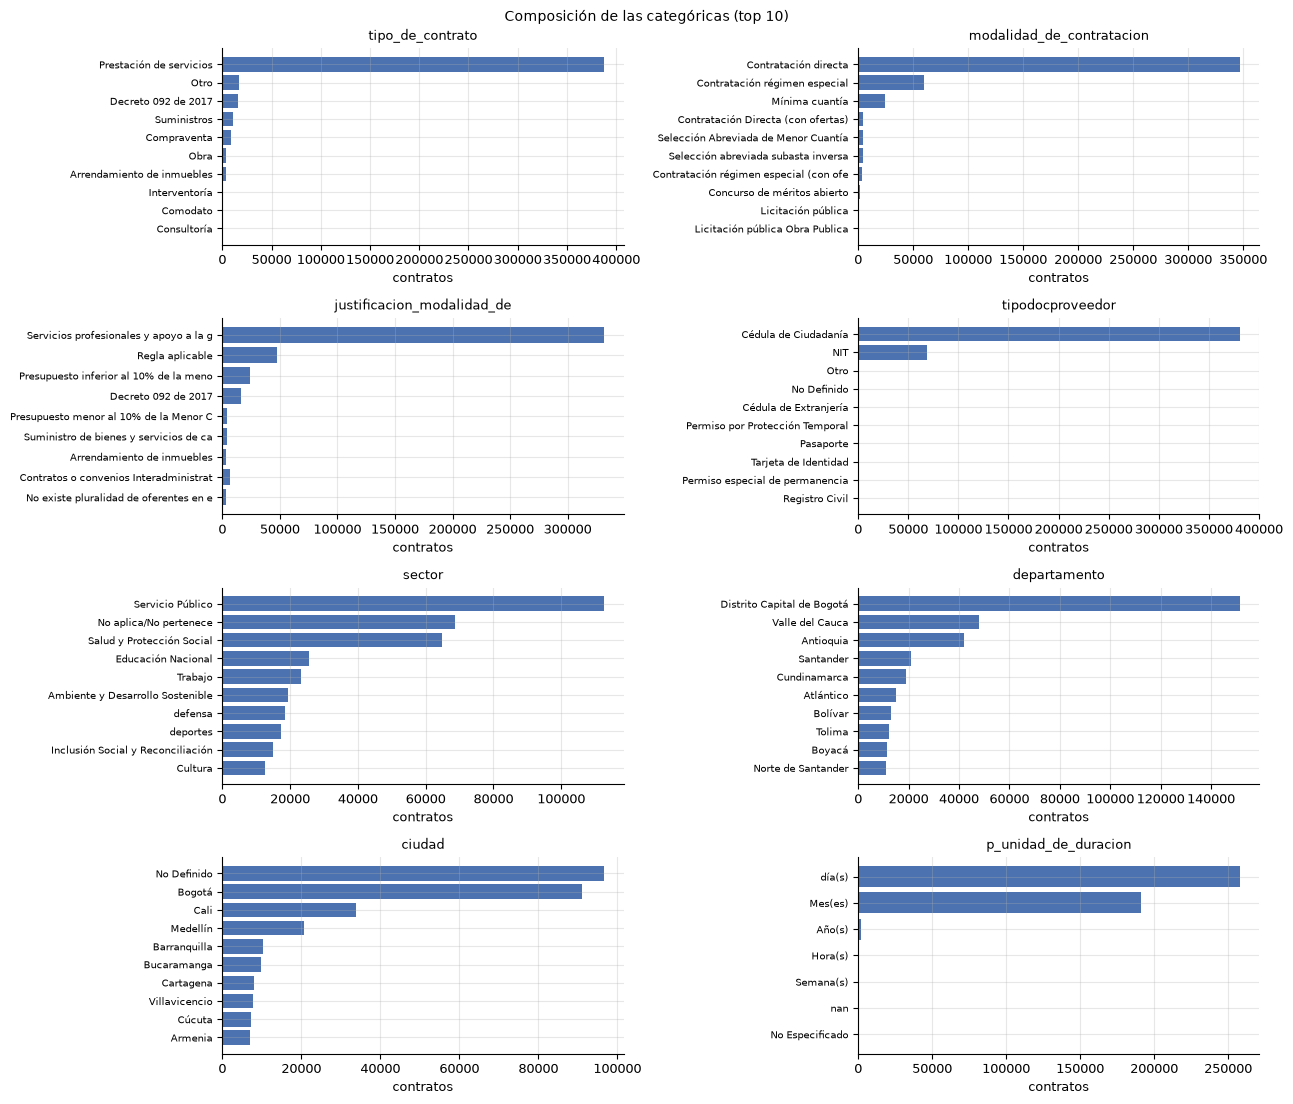

In [7]:
cats_plot = ["tipo_de_contrato", "modalidad_de_contratacion", "justificacion_modalidad_de",
             "tipodocproveedor", "sector", "departamento", "ciudad", "p_unidad_de_duracion"]
eda.graficar_barras_categoricas(X, cats_plot, top=10, ncols=2,
                                titulo="Composición de las categóricas (top 10)")
plt.show()

### 3.3 Deriva numérica por año

**Qué se observa.** 2019 es atípico y 2020–2021 cambian la composición; 2023–2025 son más estables. Las medianas de duración se mueven entre 111 y 125 días; el precio base mediano baja de 17,33 (2019) a 16,64–16,80 (2020–2025); la competencia tiene ceros altos en todos los años (entre 39 % y 99 % según la variable). El cambio más fuerte está en las categóricas (§3.4), no en las numéricas.

**Decisión.** No usar `anio_firma` como feature. Ajustar imputación/escalado solo con train y validar temporalmente. En J3, probar como sensibilidad excluir 2019 del train; el plan fija 2019–2023, así que no se cambia hoy.

,mediana_inicio,mediana_fin,cambio_abs,z_max,cambio_2023_2024
dias_publicacion_a_firma,4.00,1.00,-3.00,2.45,0.00
log_precio_base,17.37,16.87,-0.50,2.36,-0.01
mes_firma,2.00,5.00,3.00,2.16,1.00
p_dur_dias,180.00,120.00,-60.00,2.06,-4.00
dias_firma_a_inicio,0.00,1.00,1.00,1.87,0.00
len_objeto,227.00,236.00,9.00,1.79,3.00
log_pago_adelantado,0.00,0.00,0.00,0.00,0.00
fin_planeado_cruza_anio,0.00,0.00,0.00,0.00,0.00
dia_semana,2.00,2.00,0.00,0.00,0.00
firma_ultimo_trimestre,0.00,0.00,0.00,0.00,0.00


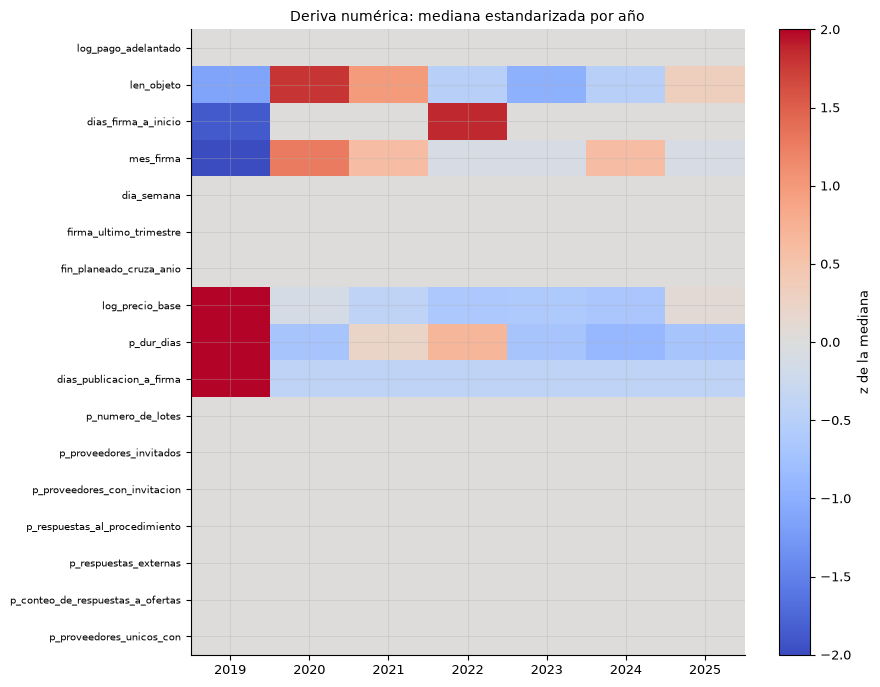

In [8]:
X_anio = X.assign(anio_firma=base["anio_firma"])
medianas, z, cambios = eda.deriva_numericas(X_anio, num_plot)
display(cambios.round(2))
eda.graficar_deriva_numericas(z, titulo="Deriva numérica: mediana estandarizada por año")
plt.show()

### 3.4 Deriva categórica por año

**Qué se observa.** Entre 2019 y 2025: cédula 44,6 %→82,4 %, NIT 53,1 %→17,1 %, contratación directa 24,2 %→72,5 %, prestación de servicios 52,0 %→82,9 %, UNSPSC 80 30,7 %→70,1 %, mínima cuantía 38,3 %→6,0 %. El salto ocurre en 2020–2021 y se estabiliza desde 2023.

**Decisión.** Misma que §3.3: no usar el año como feature; el preprocesamiento se ajusta con train. Reportar la deriva en §3.9 (monitoreo) y no comparar composiciones de 2019 con 2024 sin tenerla en cuenta.

,columna,top_inicio,pct_inicio,top_fin,pct_fin,cambio_max_pp,categoria_cambio
0,modalidad_de_contratacion,Contratación directa,59.57,Contratación directa,75.59,16.02,Contratación directa
1,unspsc_segmento,80,62.57,80,72.29,9.72,80
2,tipodocproveedor,Cédula de Ciudadanía,75.55,Cédula de Ciudadanía,84.85,9.29,Cédula de Ciudadanía
3,tipo_de_contrato,Prestación de servicios,79.59,Prestación de servicios,85.60,6.02,Prestación de servicios


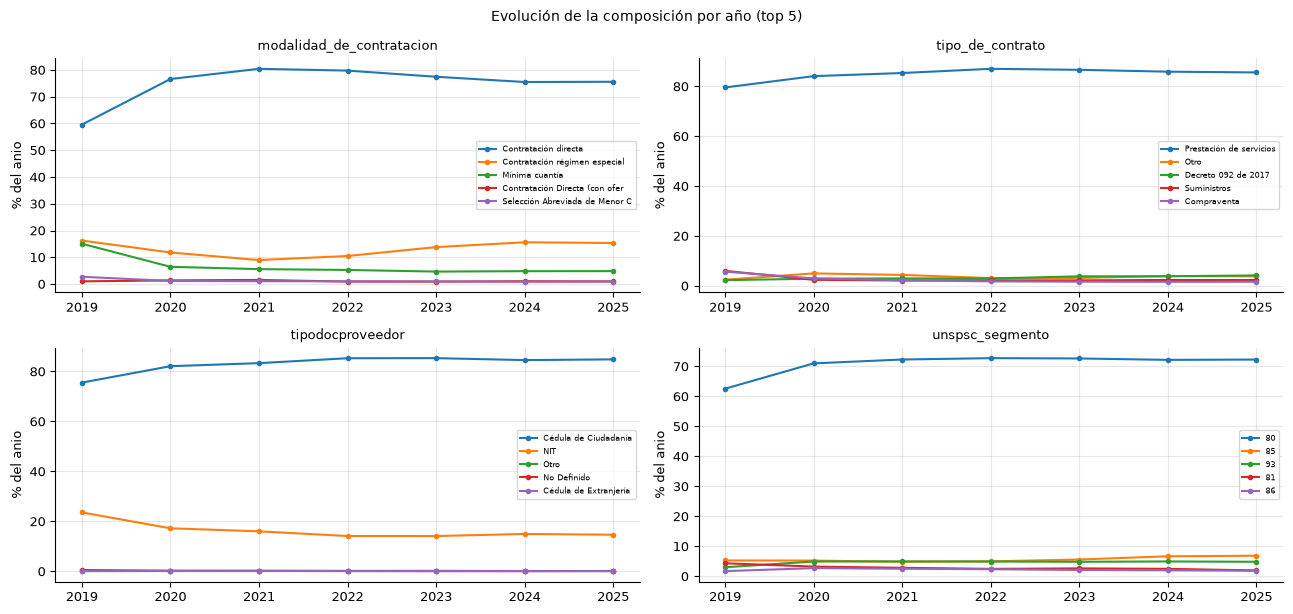

In [9]:
cats_deriva = ["modalidad_de_contratacion", "tipo_de_contrato", "tipodocproveedor", "unspsc_segmento"]
display(eda.resumen_deriva_categoricas(X_anio, cats_deriva).round(2))
eda.graficar_evolucion_categorias(X_anio, cats_deriva, top=5, ncols=2,
                                  titulo="Evolución de la composición por año (top 5)")
plt.show()

### 3.5 Matriz de correlación de las numéricas

**Qué se observa.** Se excluye `p_proveedores_que_manifestaron` porque es constante 0. Con Spearman, hay dos pares casi duplicados: `p_proveedores_invitados` y `p_proveedores_con_invitacion` (r = 0,996; el segundo nunca es mayor y es igual en 99,59 % de las filas) y `p_respuestas_al_procedimiento` y `p_proveedores_unicos_con` (r = 0,995; iguales en 99,04 %). `mes_firma` y `firma_ultimo_trimestre` correlacionan 0,753 porque el flag es una transformación del mes. Con Pearson, `dias_firma_a_inicio` y `dias_publicacion_a_firma` dan −0,743, pero con Spearman solo −0,101: la correlación la producen los valores extremos, no el grueso de los datos. En Pearson, `p_respuestas_al_procedimiento` y `p_proveedores_unicos_con` siguen en 0,971, mientras que `p_proveedores_invitados` y `p_proveedores_con_invitacion` caen a 0,073 porque casi siempre valen 0 y su relación es de orden, no lineal.

**Qué implica para kNN y SVM.** La colinealidad no rompe el modelo, pero duplica el peso de la misma señal en la distancia y en el kernel. Para kNN/SVM: dejar un representante de cada par redundante (`p_proveedores_invitados` y `p_respuestas_al_procedimiento`), y para el calendario quedarse con `firma_ultimo_trimestre` o codificar el mes de forma cíclica. Para HGB, que parte el espacio por variable, la colinealidad importa menos: se pueden mantener las dos y la ablación de J3 decide.

**Decisión.** Para kNN/SVM: eliminar `p_proveedores_que_manifestaron` (constante 0), `p_proveedores_con_invitacion` y `p_proveedores_unicos_con`, y no usar `mes_firma` junto con `firma_ultimo_trimestre`. Para HGB: mantener todas y medir en J3. Evidencia: correlaciones y duplicación de filas.

Spearman |r| >= 0,7:


,feature_1,feature_2,r,abs_r
0,p_proveedores_invitados,p_proveedores_con_invitacion,0.994,0.994
1,p_respuestas_al_procedimiento,p_proveedores_unicos_con,0.992,0.992


Pearson |r| >= 0,7:


,feature_1,feature_2,r,abs_r
0,p_respuestas_al_procedimiento,p_proveedores_unicos_con,0.983,0.983
1,mes_firma,firma_ultimo_trimestre,0.722,0.722


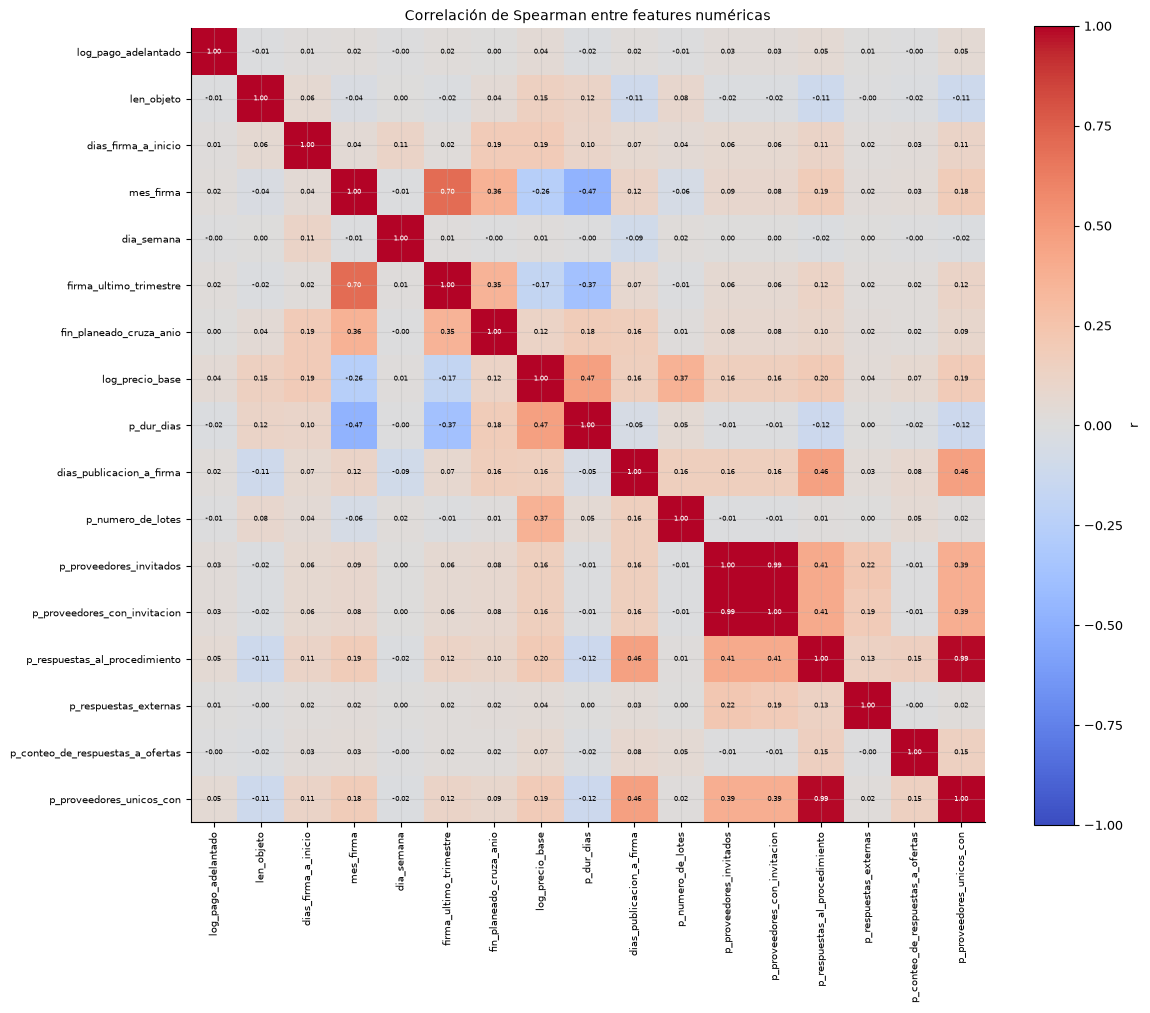

In [10]:
num_corr = [c for c in F.FEATURES_NUM if X[c].nunique() > 1]
corr_s = eda.matriz_correlacion(X, num_corr, metodo="spearman")
pares_s = eda.pares_correlacionados(corr_s, umbral=0.7)
corr_p = X[num_corr].corr(method="pearson")
pares_p = eda.pares_correlacionados(corr_p, umbral=0.7)

print("Spearman |r| >= 0,7:")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pares_s)
print("Pearson |r| >= 0,7:")
with pd.option_context("display.float_format", "{:.3f}".format):
    display(pares_p)
eda.graficar_matriz_correlacion(corr_s, titulo="Correlación de Spearman entre features numéricas")
plt.show()

## 4. Duración planeada y madurez (censura)

La madurez es mecánica: `eval_madura = fin planeado + 60 días <= fecha de corte`, con `fin planeado = inicio (o firma) + duración del proceso`. No depende de la etiqueta; la relación entre madurez y `y` se ve en §4.3 con v1.

**Qué se observa.** La duración mediana es 111–125 días; el 5,18 % tiene duración ≤ 0 y el 0,26 % no tiene duración. La fracción madura va de 99,85 % (2019) a 97,37 % (2025); en total 99,2 %. Los 1.360 inmaduros son 436 sin duración y 924 con fin planeado + 60 días después del corte.

**Decisión.** Entrenar y evaluar solo con `eval_madura = True`; imputar `p_dur_dias` para las features, pero no usar `eval_*` como features. Reportar métricas por tramo de duración (≤ 3, 3–6, 6–12, > 12 meses) en la evaluación (requisito 3.7).

,n,dur_mediana,dur_p95,pct_sin_duracion,pct_duracion_le0,pct_duracion_gt3650,pct_madura
anio_firma,,,,,,,
2019,14407,180.00,352.00,0.10,1.97,0.01,99.99
2020,36107,120.00,346.00,0.06,4.02,0.06,99.91
2021,56469,140.00,344.00,0.12,4.65,0.03,99.82
2022,71091,150.00,345.00,0.11,5.79,0.04,99.73
2023,83757,120.00,330.00,0.12,6.25,0.02,99.69
2024,88546,116.00,330.00,0.47,5.84,0.01,99.48
2025,102117,120.00,330.00,0.10,5.56,0.03,97.64


,n,pct,pct_madura
tramo,,,
<=30,42517,9.40,100.00
31-90,108000,23.87,100.00
91-180,144602,31.96,99.99
181-365,126781,28.02,99.35
366-3650,5104,1.13,68.53
>3650,125,0.03,0.00
Sin duracion / <=0,25365,5.61,96.54


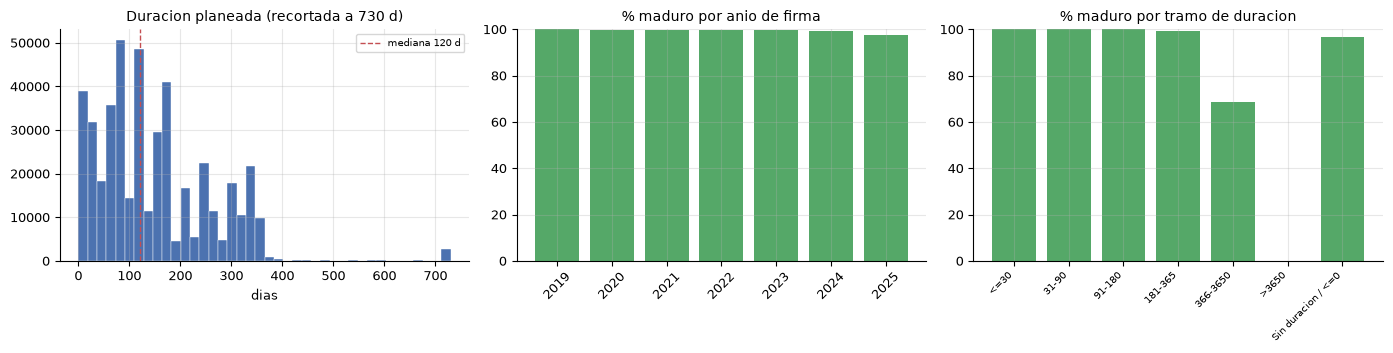

In [11]:
por_anio, por_tramo = eda.resumen_duracion_madurez(base)
display(por_anio)
display(por_tramo)
eda.graficar_duracion_madurez(base, por_anio, por_tramo)
plt.show()

### 4.3 [PROVISIONAL v0] Madurez y etiqueta

Se completa con la v1, junto con la interpretación de §5 y §6. Hoy no se interpreta: la etiqueta v0 esconde la mitad de las prórrogas y la relación entre censura y `y` puede cambiar con la v1.

## 5. Etiqueta `y` frente a `y_dias` por año [PROVISIONAL v0]

La v0 usa `y = y_dias = dias_adicionados > 0`; `y_modif` está vacía. La tabla compara las tres columnas por año y cuenta las discrepancias entre `y` y `y_dias`. Con la v1, `y` será la etiqueta de ampliación del plazo y esta sección medirá cuánto cambia la tasa.

> **Nota.** En v0 no hay datos de Modificaciones, así que y_modif está vacío e y coincide con y_dias por construcción. La comparación real de etiquetas se hace con la v1.

In [12]:
comp = eda.comparar_etiquetas(base, etiquetas=("y", "y_dias", "y_modif"))
display(eda.tasas_en_pct(comp).round(2))
display(eda.discrepancias_etiquetas(base))
print("Contratos con y_modif no nula:", int(base["y_modif"].notna().sum()))

,anio_firma,etiqueta,n,n_validos,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,2019,y,14407,14407,3192,22.16,21.49,22.84
1,2019,y_dias,14407,14407,1623,11.27,10.76,11.79
2,2019,y_modif,14407,14407,3188,22.13,21.46,22.81
3,2020,y,36107,36107,10592,29.34,28.87,29.81
4,2020,y_dias,36107,36107,4708,13.04,12.70,13.39
5,2020,y_modif,36107,36107,10581,29.30,28.84,29.78
6,2021,y,56469,56469,15698,27.80,27.43,28.17
7,2021,y_dias,56469,56469,5528,9.79,9.55,10.04
8,2021,y_modif,56469,56469,15693,27.79,27.42,28.16
9,2022,y,71091,71091,20907,29.41,29.07,29.74


,anio_firma,n,comparables,a_1_b_0,a_0_b_1,iguales
0,2019,14407,14407,1569,0,12838
1,2020,36107,36107,5884,0,30223
2,2021,56469,56469,10170,0,46299
3,2022,71091,71091,14194,0,56897
4,2023,83757,83757,14565,0,69192
5,2024,88546,88546,11136,0,77410
6,2025,102117,102117,7241,0,94876


Contratos con y_modif no nula: 452494


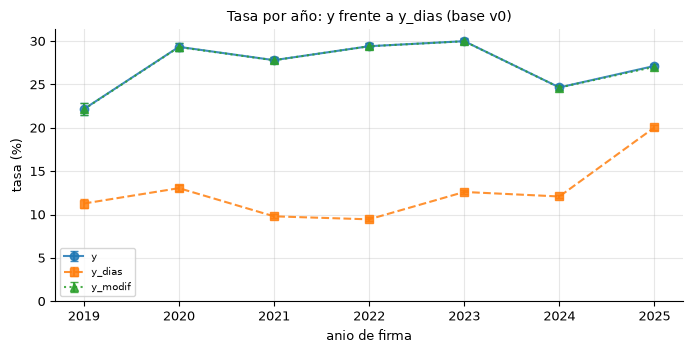

In [13]:
eda.graficar_comparacion_etiquetas(
    comp, titulo="Tasa por año: y frente a y_dias (base v0)"
)
plt.show()

**[Interpretación pendiente v1].** Aquí irá qué se observa en la comparación y la decisión sobre la etiqueta (Decisión / Alternativas / Por qué / Evidencia).

## 6. Hipótesis H1–H7 [PROVISIONAL v0]

Tasa de `y` por grupo con intervalo de Wilson del 95 %. Cada subsección deja la tabla y la gráfica; la interpretación y la decisión se completan con la v1. La muestra no es proporcional por año, así que las tasas agrupadas describen la muestra, no la población.

In [14]:
Xy = X.assign(y=base["y"], anio_firma=base["anio_firma"])

### 6.1 H1. Procesos apresurados

Tasa de `y` por tramos de `dias_publicacion_a_firma` (días entre la publicación del proceso y la firma). `Sin dato` agrupa los 229 contratos sin fecha de publicación.

,dias_publicacion_a_firma,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,165613,42237,25.50,25.29,25.71
1,1-7,216256,61277,28.34,28.15,28.53
2,8-15,33810,9410,27.83,27.36,28.31
3,16-30,21228,6629,31.23,30.61,31.85
4,31-60,9738,3898,40.03,39.06,41.01
5,61-120,3259,1193,36.61,34.97,38.28
6,>120,2210,328,14.84,13.42,16.38
7,Sin dato,380,76,20.00,16.29,24.31


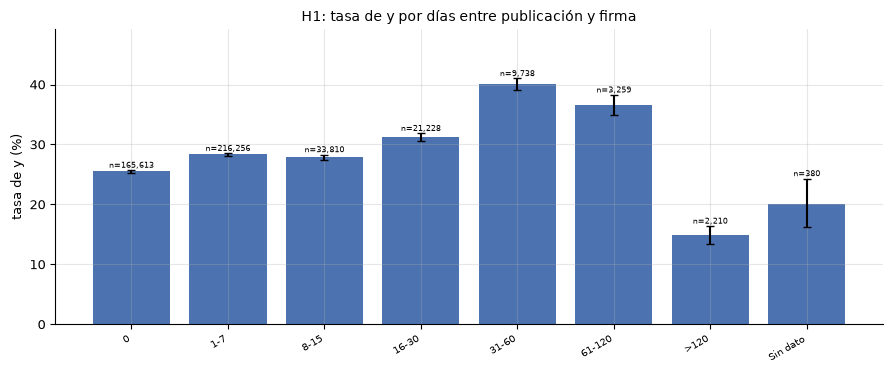

In [15]:
tabla_h1 = eda.tasa_por_tramos(
    Xy, "dias_publicacion_a_firma",
    bins=[-np.inf, 0, 7, 15, 30, 60, 120, np.inf],
    labels=["0", "1-7", "8-15", "16-30", "31-60", "61-120", ">120"],
)
display(eda.tasas_en_pct(tabla_h1).round(2))
eda.graficar_tasa_por_grupo(
    tabla_h1, col_grupo="dias_publicacion_a_firma",
    titulo="H1: tasa de y por días entre publicación y firma",
)
plt.show()

**[Interpretación pendiente v1].** Qué se observa en los tramos y qué decisión motiva (Decisión / Alternativas / Por qué / Evidencia).

### 6.2 H2. Poca competencia

Tasa de `y` por tramos de respuestas al procedimiento y de proveedores invitados. Los conteos son cero-inflados: la mayoría de los procesos no registra respuestas ni invitados.

,p_respuestas_al_procedimiento,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,408894,112539,27.52,27.39,27.66
1,1,18009,4530,25.15,24.53,25.79
2,2-3,11449,2924,25.54,24.75,26.35
3,4-9,9530,2900,30.43,29.51,31.36
4,10+,4263,2087,48.96,47.46,50.46
5,Sin dato,349,68,19.48,15.67,23.96


,p_proveedores_invitados,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,442688,121527,27.45,27.32,27.58
1,1-4,4996,1602,32.07,30.79,33.37
2,5-9,1079,442,40.96,38.07,43.93
3,10+,3382,1409,41.66,40.01,43.33
4,Sin dato,349,68,19.48,15.67,23.96


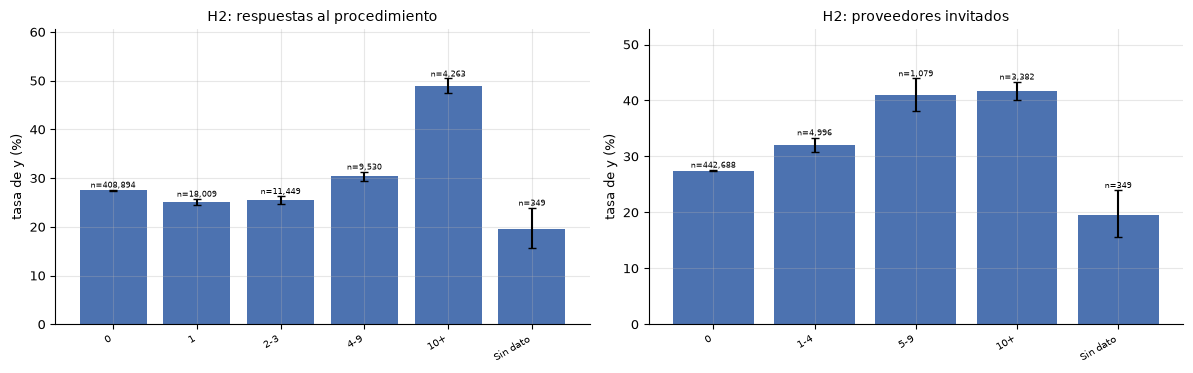

In [16]:
tabla_h2_resp = eda.tasa_por_tramos(
    Xy, "p_respuestas_al_procedimiento",
    bins=[-np.inf, 0, 1, 3, 9, np.inf],
    labels=["0", "1", "2-3", "4-9", "10+"],
)
tabla_h2_inv = eda.tasa_por_tramos(
    Xy, "p_proveedores_invitados",
    bins=[-np.inf, 0, 4, 9, np.inf],
    labels=["0", "1-4", "5-9", "10+"],
)
display(eda.tasas_en_pct(tabla_h2_resp).round(2))
display(eda.tasas_en_pct(tabla_h2_inv).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
eda.graficar_tasa_por_grupo(
    tabla_h2_resp, col_grupo="p_respuestas_al_procedimiento",
    titulo="H2: respuestas al procedimiento", ax=axes[0],
)
eda.graficar_tasa_por_grupo(
    tabla_h2_inv, col_grupo="p_proveedores_invitados",
    titulo="H2: proveedores invitados", ax=axes[1],
)
plt.show()

**[Interpretación pendiente v1].** Qué se observa en competencia y qué decisión motiva (Decisión / Alternativas / Por qué / Evidencia).

### 6.3 H3. Modalidad de contratación

Tasa de `y` por modalidad. Se muestran las 12 modalidades más frecuentes; el resto queda en `OTROS`.

,modalidad_de_contratacion,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Contratación directa,347300,87635,25.23,25.09,25.38
1,Contratación régimen especial,60145,24479,40.70,40.31,41.09
2,Mínima cuantía,24468,4407,18.01,17.53,18.50
3,Contratación Directa (con ofertas),4833,1533,31.72,30.42,33.05
4,Selección Abreviada de Menor Cuantía,4623,1920,41.53,40.12,42.96
5,Selección abreviada subasta inversa,4141,1512,36.51,35.06,37.99
6,Contratación régimen especial (con ofertas),3463,1250,36.10,34.51,37.71
7,Concurso de méritos abierto,1284,846,65.89,63.25,68.43
8,Licitación pública,1184,699,59.04,56.21,61.80
9,Licitación pública Obra Publica,810,642,79.26,76.33,81.91


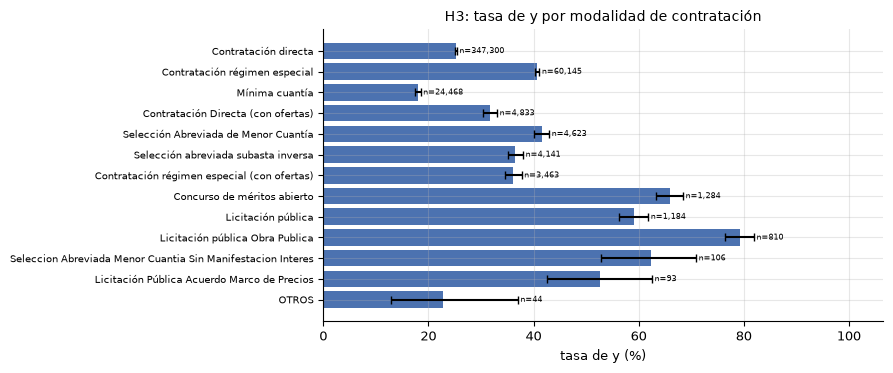

In [17]:
tabla_h3 = eda.tasa_top_categorias(Xy, "modalidad_de_contratacion", top=12)
display(eda.tasas_en_pct(tabla_h3).round(2))
eda.graficar_tasa_por_grupo(
    tabla_h3, col_grupo="modalidad_de_contratacion",
    titulo="H3: tasa de y por modalidad de contratación", horizontal=True,
)
plt.show()

**[Interpretación pendiente v1].** Qué se observa por modalidad y qué decisión motiva (Decisión / Alternativas / Por qué / Evidencia).

### 6.4 H4. Anualidad presupuestal

Tasa de `y` por mes de firma y por el indicador `firma_ultimo_trimestre` (1 = octubre–diciembre).

,mes_firma,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,1,82120,27817,33.87,33.55,34.20
1,2,63897,22069,34.54,34.17,34.91
2,3,35669,11456,32.12,31.63,32.60
3,4,24962,7020,28.12,27.57,28.68
4,5,26881,7850,29.20,28.66,29.75
5,6,26565,7860,29.59,29.04,30.14
6,7,33062,8323,25.17,24.71,25.64
7,8,34231,8433,24.64,24.18,25.09
8,9,35200,6839,19.43,19.02,19.85
9,10,33551,6084,18.13,17.72,18.55


,firma_ultimo_trimestre,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,0,362587,107667,29.69,29.55,29.84
1,1,89907,17381,19.33,19.08,19.59


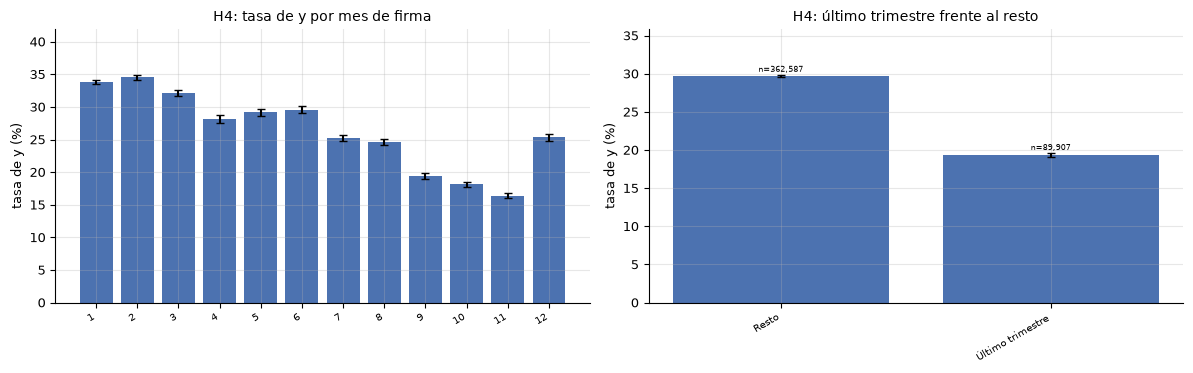

In [18]:
tabla_h4_mes = eda.tasa_por_grupo(Xy, "mes_firma")
tabla_h4_mes["mes_firma"] = tabla_h4_mes["mes_firma"].astype(int)
tabla_h4_flag = eda.tasa_por_grupo(Xy, "firma_ultimo_trimestre")
tabla_h4_flag["firma_ultimo_trimestre"] = tabla_h4_flag["firma_ultimo_trimestre"].astype(int)
tabla_h4_flag_plot = tabla_h4_flag.assign(
    firma_ultimo_trimestre=tabla_h4_flag["firma_ultimo_trimestre"].map({0: "Resto", 1: "Último trimestre"})
)
display(eda.tasas_en_pct(tabla_h4_mes).round(2))
display(eda.tasas_en_pct(tabla_h4_flag).round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
eda.graficar_tasa_por_grupo(
    tabla_h4_mes, col_grupo="mes_firma",
    titulo="H4: tasa de y por mes de firma", ax=axes[0], mostrar_n=False,
)
eda.graficar_tasa_por_grupo(
    tabla_h4_flag_plot, col_grupo="firma_ultimo_trimestre",
    titulo="H4: último trimestre frente al resto", ax=axes[1],
)
plt.show()

**[Interpretación pendiente v1].** Qué se observa en el calendario y qué decisión motiva (Decisión / Alternativas / Por qué / Evidencia).

### 6.5 H5. Plazos subestimados

Tasa de `y` por la duración planeada relativa a la mediana de su familia UNSPSC (`p_dur_dias / mediana de la familia`) y por la duración absoluta en días. La mediana de referencia se calcula con 2019–2023 y duración > 0.

,duracion_relativa,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=0,24099,5908,24.52,23.98,25.06
1,"(0, 0.5]",94724,18872,19.92,19.67,20.18
2,"(0.5, 1]",132540,36113,27.25,27.01,27.49
3,"(1, 1.5]",84427,25470,30.17,29.86,30.48
4,"(1.5, 2]",55873,22617,40.48,40.07,40.89
5,"(2, 3]",47255,12410,26.26,25.87,26.66
6,>3,8951,2200,24.58,23.70,25.48
7,Sin dato,4625,1458,31.52,30.20,32.88


,p_dur_dias,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=0,24566,6077,24.74,24.20,25.28
1,1-30,42517,8711,20.49,20.11,20.87
2,31-90,108000,24899,23.05,22.80,23.31
3,91-180,144602,40288,27.86,27.63,28.09
4,181-365,126781,42764,33.73,33.47,33.99
5,366-730,2951,1685,57.10,55.31,58.87
6,>730,2278,504,22.12,20.47,23.88
7,Sin dato,799,120,15.02,12.71,17.66


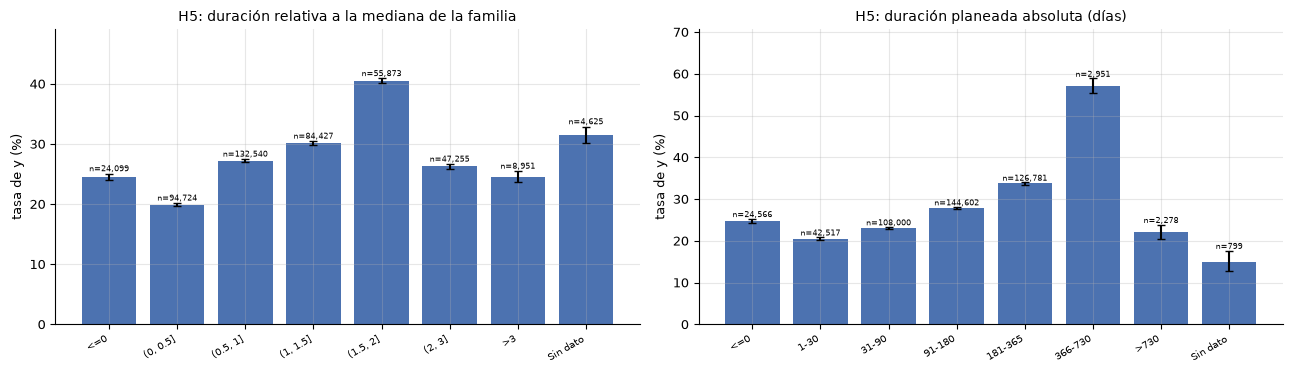

In [19]:
dur_h5 = eda.duracion_relativa_objeto(Xy, anio_referencia=2023)
Xy = Xy.assign(duracion_relativa=dur_h5["duracion_relativa"])
tabla_h5_rel = eda.tasa_por_tramos(
    Xy, "duracion_relativa",
    bins=[-np.inf, 0, 0.5, 1, 1.5, 2, 3, np.inf],
    labels=["<=0", "(0, 0.5]", "(0.5, 1]", "(1, 1.5]", "(1.5, 2]", "(2, 3]", ">3"],
)
tabla_h5_abs = eda.tasa_por_tramos(
    Xy, "p_dur_dias",
    bins=[-np.inf, 0, 30, 90, 180, 365, 730, np.inf],
    labels=["<=0", "1-30", "31-90", "91-180", "181-365", "366-730", ">730"],
)
display(eda.tasas_en_pct(tabla_h5_rel).round(2))
display(eda.tasas_en_pct(tabla_h5_abs).round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
eda.graficar_tasa_por_grupo(
    tabla_h5_rel, col_grupo="duracion_relativa",
    titulo="H5: duración relativa a la mediana de la familia", ax=axes[0],
)
eda.graficar_tasa_por_grupo(
    tabla_h5_abs, col_grupo="p_dur_dias",
    titulo="H5: duración planeada absoluta (días)", ax=axes[1],
)
plt.show()

**[Interpretación pendiente v1].** Qué se observa en duración y qué decisión motiva (Decisión / Alternativas / Por qué / Evidencia).

### 6.6 H6. Hábitos de la entidad

Tasa de `y` en 2024 por grupo de la tasa histórica de la entidad (2019–2023): `Sin historia`, `Tasa 0` y terciles `T1`–`T3` de las entidades con tasa > 0. `T1` es el tercil de menor tasa histórica y `T3` el de mayor; `Sin historia` agrupa las entidades que no aparecen antes de 2024. Los terciles se arman sobre el rank de la tasa para que los empates no los colapsen. La tabla principal agrega mínimo, mediana y máximo de la tasa histórica por grupo; el resumen por entidad muestra cómo los empates se reparten entre grupos.

,grupo_hist,n,positivos,n_entidades,tasa_pct,ic_inf_pct,ic_sup_pct,tasa_hist_min_pct,tasa_hist_mediana_pct,tasa_hist_max_pct
0,Sin historia,1833,211,317,11.51,10.13,13.05,NaN,NaN,NaN
1,Tasa 0,6460,735,553,11.38,10.63,12.18,0.00,0.00,0.00
2,T1,21231,3030,416,14.27,13.81,14.75,0.40,10.34,16.42
3,T2,31741,6513,423,20.52,20.08,20.97,16.48,22.56,30.59
4,T3,27281,11342,377,41.57,40.99,42.16,30.71,42.86,100.00


,grupo,entidades,tasa_min_pct,tasa_mediana_pct,tasa_max_pct
0,T1,439,0.40,10.34,16.42
1,T2,439,16.48,22.56,30.59
2,T3,439,30.71,42.86,100.00
3,Tasa 0,1017,0.00,0.00,0.00


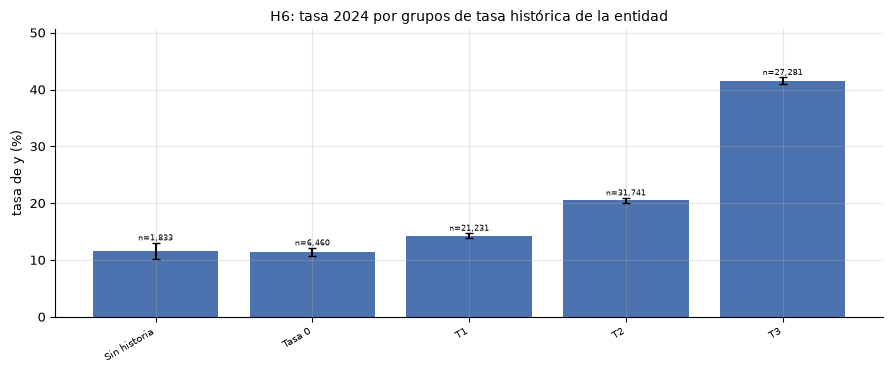

In [20]:
tabla_h6, hist_h6 = eda.tasa_entidad_historica(base, anio_objetivo=2024)
resumen_h6 = (
    hist_h6.groupby("grupo", observed=False)
    .agg(entidades=("tasa", "size"), tasa_min=("tasa", "min"),
         tasa_mediana=("tasa", "median"), tasa_max=("tasa", "max"))
    .reset_index()
)
display(eda.tasas_en_pct(tabla_h6).round(2))
display(eda.tasas_en_pct(resumen_h6).round(2))
eda.graficar_tasa_por_grupo(
    tabla_h6, col_grupo="grupo_hist",
    titulo="H6: tasa 2024 por grupos de tasa histórica de la entidad",
)
plt.show()

**[Interpretación pendiente v1].** Qué se observa en los hábitos de la entidad y qué decisión motiva (Decisión / Alternativas / Por qué / Evidencia).

### 6.7 H7. Tipo de objeto

Tasa de `y` por segmento y familia UNSPSC, por tipo de contrato y por longitud del objeto (proxy de complejidad). En segmento, familia y tipo se muestran las 10 categorías más frecuentes; el resto queda en `OTROS`.

,unspsc_segmento,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,80,323045,87160,26.98,26.83,27.13
1,85,26352,10147,38.51,37.92,39.09
2,93,21784,6951,31.91,31.29,32.53
3,81,11535,3249,28.17,27.35,28.99
4,86,9692,2247,23.18,22.35,24.03
5,72,7355,2858,38.86,37.75,39.98
6,84,3811,965,25.32,23.97,26.73
7,Sin dato,3806,1331,34.97,33.47,36.50
8,77,3605,821,22.77,21.43,24.17
9,78,3344,848,25.36,23.91,26.86


,unspsc_familia,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,8011,285020,77576,27.22,27.05,27.38
1,8510,19289,8429,43.70,43.00,44.40
2,8016,14181,3469,24.46,23.76,25.18
3,8010,12386,3279,26.47,25.70,27.26
4,9314,11844,3901,32.94,32.10,33.79
5,9315,8337,2680,32.15,31.15,33.16
6,8610,6485,1565,24.13,23.11,25.19
7,8012,5257,1178,22.41,21.30,23.56
8,8512,5081,1271,25.01,23.84,26.22
9,8110,4715,1833,38.88,37.49,40.28


,tipo_de_contrato,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,Prestación de servicios,388023,105320,27.14,27.00,27.28
1,Otro,16849,6387,37.91,37.18,38.64
2,Decreto 092 de 2017,15978,4050,25.35,24.68,26.03
3,Suministros,10780,2292,21.26,20.50,22.04
4,Compraventa,8917,1959,21.97,21.12,22.84
5,Obra,4081,2116,51.85,50.32,53.38
6,Arrendamiento de inmuebles,3494,1178,33.71,32.17,35.30
7,Interventoría,1043,749,71.81,69.01,74.46
8,Comodato,1040,171,16.44,14.31,18.82
9,Consultoría,889,377,42.41,39.20,45.68


,len_objeto,n,positivos,tasa_pct,ic_inf_pct,ic_sup_pct
0,<=50,5863,3398,57.96,56.69,59.21
1,51-100,17915,6154,34.35,33.66,35.05
2,101-200,142903,36088,25.25,25.03,25.48
3,201-400,239544,67642,28.24,28.06,28.42
4,>400,46269,11766,25.43,25.03,25.83


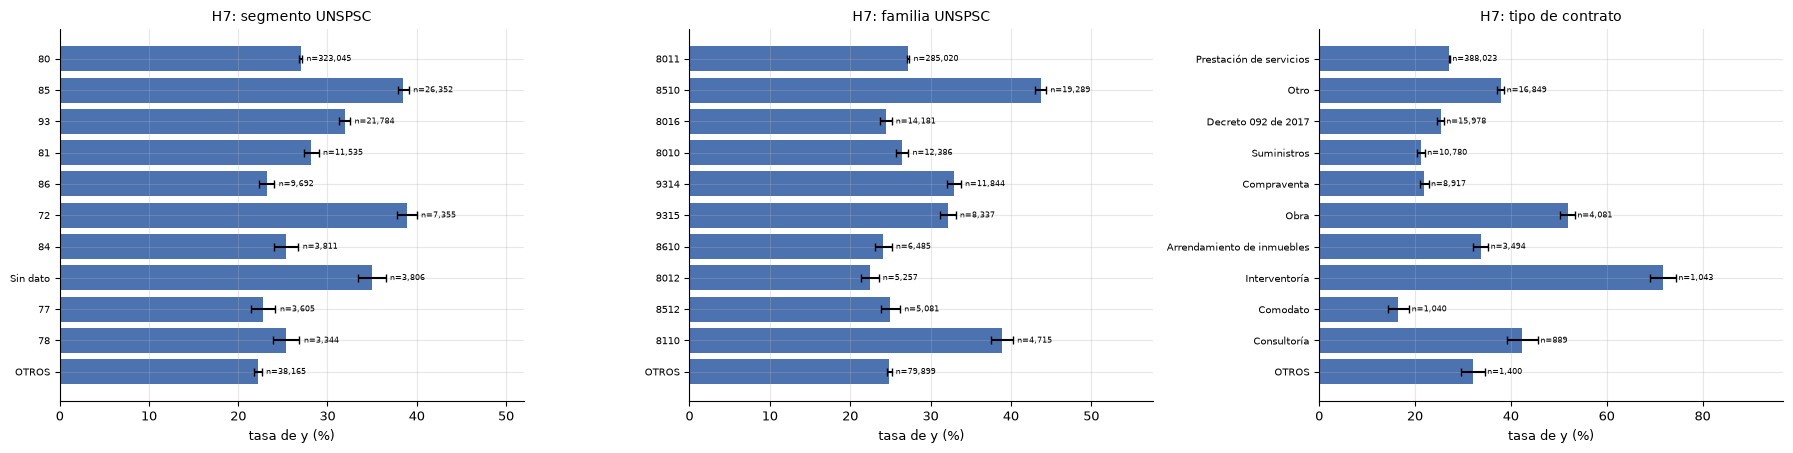

In [21]:
tabla_h7_seg = eda.tasa_top_categorias(Xy, "unspsc_segmento", top=10)
tabla_h7_fam = eda.tasa_top_categorias(Xy, "unspsc_familia", top=10)
tabla_h7_tipo = eda.tasa_top_categorias(Xy, "tipo_de_contrato", top=10)
tabla_h7_len = eda.tasa_por_tramos(
    Xy, "len_objeto",
    bins=[-np.inf, 50, 100, 200, 400, np.inf],
    labels=["<=50", "51-100", "101-200", "201-400", ">400"],
)
display(eda.tasas_en_pct(tabla_h7_seg).round(2))
display(eda.tasas_en_pct(tabla_h7_fam).round(2))
display(eda.tasas_en_pct(tabla_h7_tipo).round(2))
display(eda.tasas_en_pct(tabla_h7_len).round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
eda.graficar_tasa_por_grupo(
    tabla_h7_seg, col_grupo="unspsc_segmento",
    titulo="H7: segmento UNSPSC", horizontal=True, ax=axes[0],
)
eda.graficar_tasa_por_grupo(
    tabla_h7_fam, col_grupo="unspsc_familia",
    titulo="H7: familia UNSPSC", horizontal=True, ax=axes[1],
)
eda.graficar_tasa_por_grupo(
    tabla_h7_tipo, col_grupo="tipo_de_contrato",
    titulo="H7: tipo de contrato", horizontal=True, ax=axes[2],
)
plt.show()

**[Interpretación pendiente v1].** Qué se observa por tipo de objeto y qué decisión motiva (Decisión / Alternativas / Por qué / Evidencia).

## 7. Privacidad del proveedor

**Qué se observa.** El 74,6 % de los contratos tiene proveedor con cédula de ciudadanía, 24,5 % con NIT, 0,4 % "No Definido" y 0,3 % "Otro". La composición cambia fuerte en 2019 (44,6 % cédula / 53,1 % NIT) y se estabiliza desde 2023 (82,2–82,4 % / 17,1–17,2 %). Es decir, cerca de tres de cada cuatro contratos tienen un proveedor con cédula, un dato personal.

**Decisión.**
- **Decisión:** excluir la identidad y los datos del proveedor (documento, nombre, `codigo_proveedor`, NIT adjudicado); conservar solo `tipodocproveedor`.
- **Alternativas:** historial de prórrogas del proveedor; identificador cifrado (hash); usar solo personas jurídicas (NIT); excluir.
- **Por qué:** la cédula es dato personal (Ley 1581 de 2012); el hash sigue siendo un dato personal seudonimizado y un puntaje por proveedor se convierte en un ranking de personas. El tipo de documento no identifica.
- **Evidencia:** distribución de `tipodocproveedor` y su evolución por año.
- **Costo:** se pierde una posible señal (historial del proveedor) cuyo tamaño no se midió [NO EVALUADO].

,tipo,n,pct,pct_acumulado
0,Cédula de Ciudadanía,381242,84.25,84.25
1,NIT,68844,15.21,99.47
2,Otro,878,0.19,99.66
3,No Definido,730,0.16,99.82
4,Cédula de Extranjería,607,0.13,99.96
5,Permiso por Protección Temporal,84,0.02,99.98
6,Pasaporte,45,0.01,99.99
7,Tarjeta de Identidad,42,0.01,100.00
8,Permiso especial de permanencia,17,0.00,100.00
9,Registro Civil,5,0.00,100.00


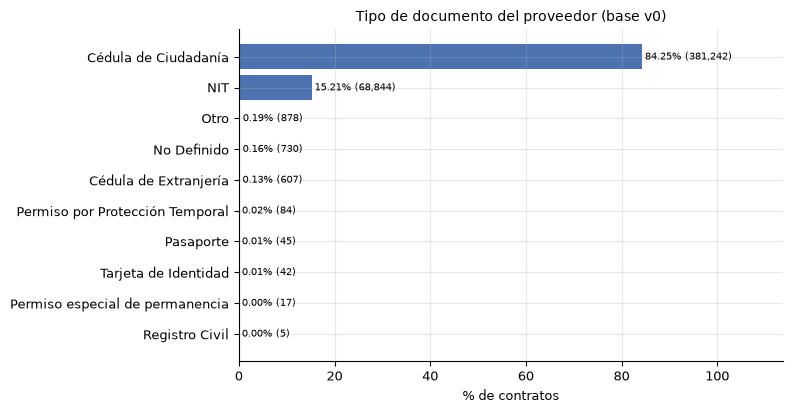

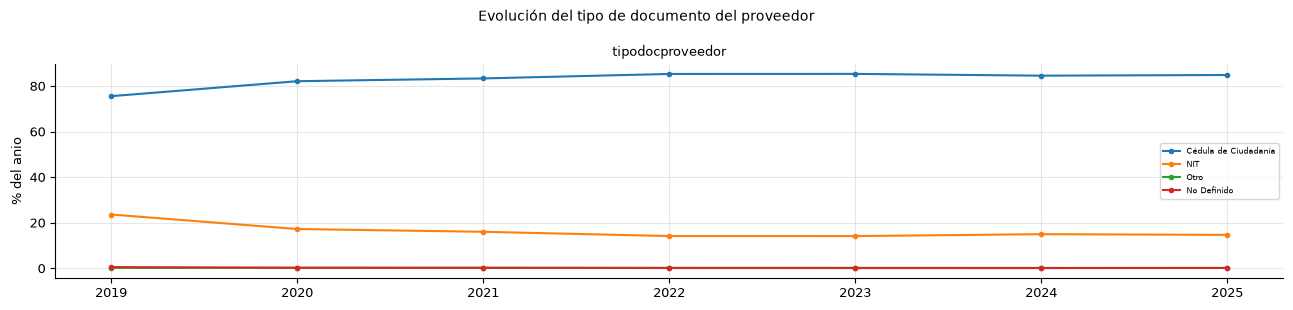

In [22]:
tipo_doc = eda.resumen_tipodocproveedor(base)
display(tipo_doc.round(2))
eda.graficar_tipodocproveedor(tipo_doc, titulo="Tipo de documento del proveedor (base v0)")
plt.show()
eda.graficar_evolucion_categorias(base, ["tipodocproveedor"], top=4, ncols=1,
                                  titulo="Evolución del tipo de documento del proveedor")
plt.show()

## 8. Fuga de información (pendiente v1)

No se puede cerrar hoy: las columnas de fuga (`estado_contrato`, `fecha_de_fin_del_contrato`, `valor_del_contrato`, montos por fuente de recursos) viven en `data/raw/` de la carpeta principal y la F3 las deja el lunes. La evidencia esperada es el contraste con y sin esas columnas: ROC-AUC/PR-AUC cerca de 0,95/0,84 con fuga frente a la referencia limpia. También queda pendiente confrontar `COLUMNAS_FUGA` con `docs/LISTA_FUGA.md` cuando exista.

**Cuando llegue la v1:** unir `data/raw` por `id_contrato`, entrenar el mismo HGB con y sin las columnas de fuga, reportar la diferencia y confirmar que ninguna entra a `FEATURES`.

## 9. Resumen de decisiones

| ID | Decisión | Alternativas | Por qué | Evidencia | Va a |
|---|---|---|---|---|---|
| D2.1 | Imputar en el Pipeline con mediana/moda + indicadores de bloque | Borrar filas; imputar con 0 | Faltantes bajos y en bloque; borrar sesga | 215 sin proceso, 1.732 sin inicio, 436 sin duración, 1.375 sin UNSPSC | J2 |
| D2.2 | Duración ≤0 → faltante y recorte [1, 3.650]; precio negativo → flag (ya queda en 0 en `log_precio_base`) | Dejar crudo; borrar outliers | 5,18 % de duraciones no positivas y colas de 83,4 M | 8.694 ≤0, 66 >3.650, 26 precios negativos | J2 |
| D2.3 | Agrupar raras <1 % en `OTROS`; HGB nativo/tope; `nit_entidad` con TargetEncoder | One-hot completo; dejar texto | Cardinalidad alta y 77 % de filas en entidades con <1 % | 2.568 entidades, 664 ciudades | J2 |
| D2.4 | Eliminar constantes/redundantes | Mantener las 18 numéricas | Duplican la misma señal | 1 constante (`p_proveedores_que_manifestaron`), 99,59 %/99,04 % iguales, r 0,996/0,995 | J2 |
| D3.1 | `log1p` en conteos + `RobustScaler` para kNN/SVM; crudo para HGB | Estandarizar sin log | Zero-inflación y colas largas | 79–99 % ceros en competencia | J2 |
| D3.2 | No usar el año como feature; ajustar solo con train | Usar año; mezclar train/test | Deriva fuerte 2019→2025 | Composición y competencia cambian | J2/J3 |
| D3.3 | Quitar redundantes para kNN/SVM; mantener para HGB | PCA | Colinealidad duplica peso | r 0,996 y 0,995 | J2/J3 |
| D3.4 | Calendario: flag de trimestre + mes cíclico o uno solo para distancia | Mes ordinal | `mes_firma` y el flag correlacionan 0,75 | r = 0,75 | J2 |
| D4.1 | Entrenar/evaluar solo maduros; `eval_*` nunca como feature | Usar todos | 99,2 % maduro; 1.360 inmaduros | Madurez 97,4–99,9 % por año | J2/J3 |
| D7.1 | Excluir identidad del proveedor; conservar solo el tipo de documento | Hash; historial; solo NIT | 74,6 % de los contratos tiene proveedor con cédula | Distribución `tipodocproveedor` | J3/app |

**Pendiente v1:** §4.3 (madurez vs `y`), §5 (`y` vs `y_dias` y tasa por año), §6 (H1–H7 con interpretación), §7.2 (tasa por tipo de documento), §8 (fuga). El detalle para Jose está en `docs/EDA_INSIGHTS_PREPROCESAMIENTO.md`.

In [23]:
print("Secciones cerradas hoy: 2, 3, 4.1-4.2, 5, 6 (tablas y gráficas), 7.1 y 9.")
print("Pendientes v1: 4.3, interpretación de 5-6, 7.2 y 8.")


Secciones cerradas hoy: 2, 3, 4.1-4.2, 5, 6 (tablas y gráficas), 7.1 y 9.
Pendientes v1: 4.3, interpretación de 5-6, 7.2 y 8.
